# 01 · Data exploration

This project trains an image-captioning model on **MS COCO 2014** ([website](https://cocodataset.org/), [paper](https://arxiv.org/abs/1405.0312)). Every training image comes with about five captions written by people, which gives roughly 414k image–caption pairs.

This notebook looks at the captions, shows how they are turned into token tensors, and explains how training batches are built.

In [1]:
import os
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))  # make project modules importable

import config

import nltk
import numpy as np
import torch
import matplotlib.pyplot as plt
from collections import Counter
from PIL import Image
from pycocotools.coco import COCO

nltk.download("punkt_tab", quiet=True)
np.random.seed(7)
print("COCO root:", os.path.relpath(config.COCO_ROOT, config.PROJECT_ROOT))
print("Device:   ", config.DEVICE)

COCO root: data
Device:    mps


## Images and their captions

Here is a random training image with all of its captions. They differ in wording and in what they focus on, so there is no single correct caption for an image.

loading annotations into memory...
Done (t=0.19s)
creating index...


index created!


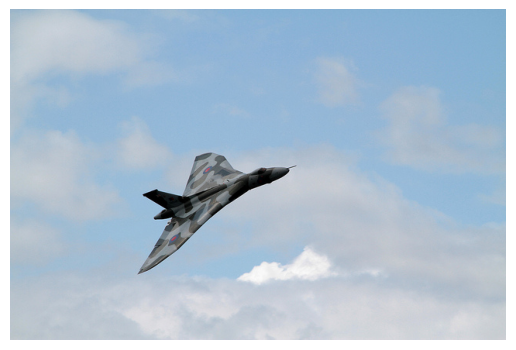

- A fighter jet flying through a blue cloud filled sky.
- A plane flying in the air during the day.
- A  jet, painted with camouflage,  flying through the air.
- There is a military aircraft flying across the sky.
- A camouflaged military plane flying on a perfect day.


In [2]:
coco_caps = COCO(config.COCO_ROOT / "cocoapi/annotations/captions_train2014.json")
img_dir = config.COCO_ROOT / "cocoapi/images/train2014"

img_id = int(np.random.choice(coco_caps.getImgIds()))
info = coco_caps.loadImgs(img_id)[0]

plt.imshow(Image.open(img_dir / info["file_name"]))
plt.axis("off")
plt.show()
for ann in coco_caps.loadAnns(coco_caps.getAnnIds(imgIds=img_id)):
    print("-", ann["caption"].strip())

## From caption to tensor

Each caption is lowercased and tokenized with NLTK. It is wrapped in the special tokens `<start>` and `<end>`, mapped to integer ids, and stored as a `LongTensor`. The vocabulary is fixed beforehand in `vocab.pkl` and is shared by training and inference.

In [3]:
from vocabulary import Vocabulary

vocab = Vocabulary(vocab_threshold=config.VOCAB_THRESHOLD,
                   vocab_file=str(config.VOCAB_FILE),
                   vocab_from_file=True)

caption = "A person doing a trick on a rail while riding a skateboard."
tokens = nltk.tokenize.word_tokenize(caption.lower())
ids = [vocab(vocab.start_word)] + [vocab(t) for t in tokens] + [vocab(vocab.end_word)]

print("tokens:", [vocab.start_word] + tokens + [vocab.end_word])
print("ids:   ", ids)
print("tensor:", torch.tensor(ids, dtype=torch.long))

Vocabulary successfully loaded from vocab.pkl file!
tokens: ['<start>', 'a', 'person', 'doing', 'a', 'trick', 'on', 'a', 'rail', 'while', 'riding', 'a', 'skateboard', '.', '<end>']
ids:    [0, 3, 98, 756, 3, 396, 39, 3, 1015, 207, 139, 3, 755, 18, 1]
tensor: tensor([   0,    3,   98,  756,    3,  396,   39,    3, 1015,  207,  139,    3,
         755,   18,    1])


In [4]:
print("Vocabulary size:", len(vocab))
for w in (vocab.start_word, vocab.end_word, vocab.unk_word):
    print(f"{w:>8} -> {vocab(w)}")
print("Out-of-vocabulary words map to <unk>:", vocab("jfkafejw"), vocab("ieowoqjf"))

Vocabulary size: 9949
 <start> -> 0
   <end> -> 1
   <unk> -> 2
Out-of-vocabulary words map to <unk>: 2 2


## Choosing the vocabulary threshold

A word joins the vocabulary only if it appears at least `vocab_threshold` times in the training captions. Raising the threshold shrinks the output softmax and drops typos and very rare words, but more words become `<unk>`. The counts below are computed directly from the annotations, so `vocab.pkl` is never rebuilt.

In [5]:
word_counts = Counter()
caption_lengths = []
for ann in coco_caps.anns.values():
    toks = nltk.tokenize.word_tokenize(ann["caption"].lower())
    word_counts.update(toks)
    caption_lengths.append(len(toks))

total = sum(word_counts.values())
print(f"{'threshold':>9} | {'vocab size':>10} | {'token coverage':>14}")
for t in (1, 2, 4, 8, 16):
    kept = {w: c for w, c in word_counts.items() if c >= t}
    print(f"{t:>9} | {len(kept) + 3:>10} | {sum(kept.values()) / total:>13.2%}")

threshold | vocab size | token coverage
        1 |      24895 |       100.00%
        2 |      14460 |        99.78%
        4 |       9949 |        99.55%
        8 |       7072 |        99.24%
       16 |       5093 |        98.78%


With a threshold of **4** the vocabulary has about 10k tokens (including the special tokens) and still covers more than 99% of the word occurrences in the training set. This is the value used for `vocab.pkl`.

## Caption lengths and length-bucketed batches

Most captions are 9–12 tokens long. Very short and very long captions are rare.

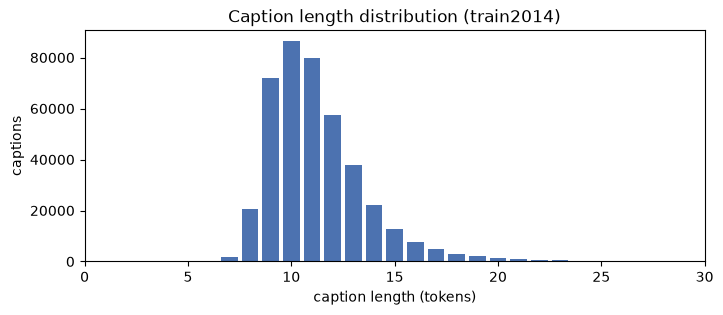

In [6]:
lengths = Counter(caption_lengths)
xs = sorted(lengths)
plt.figure(figsize=(8, 3))
plt.bar(xs, [lengths[x] for x in xs], color="#4C72B0")
plt.xlabel("caption length (tokens)")
plt.ylabel("captions")
plt.xlim(0, 30)
plt.title("Caption length distribution (train2014)")
plt.show()

The data loader avoids padding with a simple trick, following [Show, Attend and Tell](https://arxiv.org/abs/1502.03044). For each step it picks a caption length with probability proportional to how often that length occurs, and then draws the whole batch from captions of that length. Every caption in a batch is therefore the same length, and the LSTM can process the batch without masking.

In [7]:
import torch.utils.data as data
from torchvision import transforms
from data_loader import get_loader

transform_train = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225)),
])

data_loader = get_loader(transform=transform_train, mode="train", batch_size=8,
                         vocab_file=str(config.VOCAB_FILE), vocab_from_file=True,
                         cocoapi_loc=str(config.COCO_ROOT))

indices = data_loader.dataset.get_train_indices()
data_loader.batch_sampler.sampler = data.sampler.SubsetRandomSampler(indices=indices)
images, captions = next(iter(data_loader))
print("images:  ", tuple(images.shape))
print("captions:", tuple(captions.shape))

Vocabulary successfully loaded from vocab.pkl file!
loading annotations into memory...


Done (t=0.21s)
creating index...
index created!
Obtaining caption lengths for the subset...


images:   (8, 3, 224, 224)
captions: (8, 11)


## A forward pass through the model

To check the shapes, the batch goes through the encoder and decoder defined in `model.py` (with untrained heads). The decoder returns one vocabulary distribution per time step: the first step comes from the image embedding, and each later step comes from a caption token.

In [8]:
from model import EncoderCNN, DecoderRNN

encoder = EncoderCNN(config.EMBED_SIZE).to(config.DEVICE)
decoder = DecoderRNN(config.EMBED_SIZE, config.HIDDEN_SIZE, len(vocab)).to(config.DEVICE)

with torch.no_grad():
    features = encoder(images.to(config.DEVICE))
    outputs = decoder(features, captions.to(config.DEVICE))
print("features:", tuple(features.shape), " (batch, embed_size)")
print("outputs: ", tuple(outputs.shape), " (batch, caption_len, vocab_size)")

features: (8, 512)  (batch, embed_size)
outputs:  (8, 11, 9949)  (batch, caption_len, vocab_size)
